## 融合Softmax（Fused Softmax）

通过算子融合（Kernel Fusion）减少显存读写次数。

如何获取 GPU 的硬件规格和参数（GPU Specifications）。

进一步了解 GPU 架构的相关细节（GPU Architecture）。

如何利用启发式规则（Heuristics）和 GPU 特定的硬件属性来定义元参数（Meta-parameters）。

进一步了解掩码机制（Masking），以及如何为被掩码屏蔽的无效元素选择合适的填充值。

In [1]:


import torch


import triton
import triton.language as tl
from triton.runtime import driver




def naive_softmax(x):
    """Compute row-wise softmax of X using native pytorch
    使用原生 PyTorch 计算 X 的逐行 softmax


    We subtract the maximum element in order to avoid overflows. Softmax is invariant to
    this shift.
    我们减去最大元素以避免溢出。Softmax 对于这种偏移是不变的。
    """
    # read  MN elements ; write M  elements
    # 读取 MN 个元素；写入 M 个元素
    x_max = x.max(dim=1)[0]             #取出x每一行的最大值
    # read MN + M elements ; write MN elements
    # 读取 MN + M 个元素；写入 MN 个元素
    z = x - x_max[:, None]              #PyTorch 通过广播，把每行的最大值用于该行的所有列
    # read  MN elements ; write MN elements
    # 读取 MN 个元素；写入 MN 个元素
    numerator = torch.exp(z)
    # read  MN elements ; write M  elements
    # 读取 MN 个元素；写入 M 个元素
    denominator = numerator.sum(dim=1)
    # read MN + M elements ; write MN elements
    # 读取 MN + M 个元素；写入 MN 个元素
    ret = numerator / denominator[:, None]
    # in total: read 5MN + 2M elements ; wrote 3MN + 2M elements
    # 总计：读取 5MN + 2M 个元素；写入 3MN + 2M 个元素
    return ret
'''

'''

'\n\n'

对于输入矩阵 $x \in \mathbb{R}^{M \times N}$，直接使用 PyTorch
计算 `y = naive_softmax(x)` 时，需要进行以下 DRAM 读写：

- **读取元素数量**：$5MN + 2M$
- **写入元素数量**：$3MN + 2M$
- **总读写元素数量**：$8MN + 4M$

这些重复的内存访问带来了额外开销。我们希望使用一个自定义的**融合内核**，
只从 DRAM 读取一次输入 $x$，在芯片上完成所有中间计算，
然后将结果写回 DRAM。

融合后，只需读取 $MN$ 个元素并写回 $MN$ 个元素，
总读写量为 $2MN$ 个元素。若每个元素占 $b$ 字节，
则总读写量为 $2MNb$ 字节。

在性能完全受内存带宽限制的理想情况下，理论加速比约为：

$$
\text{加速比}
=
\frac{8MN + 4M}{2MN}
=
4 + \frac{2}{N}
\approx 4
$$

因此，当 $N$ 足够大时，可以预期约 **4 倍的理论加速**，
实际加速比还取决于具体实现和硬件。

`torch.jit.script` 可以尝试自动完成这种内核融合，
但正如后续实验将展示的，其效果仍不够理想。

## 计算内核
softmax 内核工作原理如下：每个程序加载输入矩阵 X 的一组行，按程序数量跨步处理，对其进行归一化，并将结果写回输出 Y。

注意，Triton 的一个重要限制是每个块必须具有 2 的幂次数的元素，因此，如果我们要处理任意可能的输入形状，我们需要在内部「填充」每一行，并适当保护内存操作。

In [2]:
@triton.jit
def softmax_kernel(output_ptr, input_ptr, input_row_stride,
                    output_row_stride, n_rows, n_cols, 
                    BLOCK_SIZE: tl.constexpr,
                   num_stages: tl.constexpr):
    # starting row of the program
    # 程序起始行
    row_start = tl.program_id(0)
    row_step = tl.num_programs(0)   #指的是第 0 维的 program 数量
    for row_idx in tl.range(row_start, n_rows, row_step, num_stages=num_stages):
        # The stride represents how much we need to increase the pointer to advance 1 row
        # 步长表示我们需要对指针增加多少以推进 1 行
        row_start_ptr = input_ptr + row_idx * input_row_stride
        # The block size is the next power of two greater than n_cols, so we can fit each
        # 块大小是大于 n_cols 的下一个二的幂，因此我们可以适配
        # row in a single block
        # 单个块中的行
        col_offsets = tl.arange(0, BLOCK_SIZE)
        input_ptrs = row_start_ptr + col_offsets
        # Load the row into SRAM, using a mask since BLOCK_SIZE may be > than n_cols
        # 将行加载到 SRAM 中，使用掩码，因为 BLOCK_SIZE 可能大于 n_cols
        mask = col_offsets < n_cols
        row = tl.load(input_ptrs, mask=mask, other=-float('inf'))
        # Subtract maximum for numerical stability
        # 为了数值稳定性而减去最大值
        row_minus_max = row - tl.max(row, axis=0)
        # Note that exponentiation in Triton is fast but approximate (i.e., think __expf in CUDA)
        # 请注意，Triton 中的指数运算速度很快，但是是近似的（例如，类似于 CUDA 中的 __expf）。
        numerator = tl.exp(row_minus_max)
        denominator = tl.sum(numerator, axis=0)
        softmax_output = numerator / denominator
        # Write back output to DRAM
        # 将输出写回 DRAM
        output_row_start_ptr = output_ptr + row_idx * output_row_stride
        output_ptrs = output_row_start_ptr + col_offsets
        tl.store(output_ptrs, softmax_output, mask=mask)

In [3]:
device = torch.cuda.current_device()    #获取当前 CUDA 设备的编号
properties = driver.active.utils.get_device_properties(device)  #通过 Triton 查询这张 GPU 的硬件属性，返回一个字典
NUM_SM = properties["multiprocessor_count"]
NUM_REGS = properties["max_num_regs"]       #每个 SM 可用于驻留线程块的 32 位寄存器资源预算
SIZE_SMEM = properties["max_shared_mem"]    #单个线程块可申请的最大共享内存，单位为字节
WARP_SIZE = properties["warpSize"]
target = triton.runtime.driver.active.get_current_target()
kernels = {}


def softmax(x):
    n_rows, n_cols = x.shape


    # 每次循环迭代的块大小是大于 `x` 列数的最小二的幂
    BLOCK_SIZE = triton.next_power_of_2(n_cols)

    # 另一个技巧是通过增加每行分配的线程数来要求编译器使用更多的线程块 (`num_warps`)
    # 将在下一个教程中看到如何以更自然的方式自动调整此值，以免自己进行手动启发式处理。
    num_warps = 8

    # 软件流水线阶段的数量
    num_stages = 4 if SIZE_SMEM > 200000 else 2#？


    # 分配输出空间
    y = torch.empty_like(x)

    # 预编译内核以获取寄存器使用情况并计算线程占用情况。
    kernel, num_programs = kernels.get(BLOCK_SIZE, (None, 0))
    if kernel is None:
        #主要用于提前编译特定配置的 Kernel，而不是重复执行 Kernel 来测量性能
        kernel = softmax_kernel.warmup(y, x, x.stride(0), y.stride(0), n_rows, n_cols, BLOCK_SIZE=BLOCK_SIZE,
                                       num_stages=num_stages, num_warps=num_warps, grid=(1, ))
        kernel._init_handles()
        n_regs = kernel.n_regs      #每个线程使用多少寄存器
        size_smem = kernel.metadata.shared
        occupancy = NUM_REGS // (n_regs * WARP_SIZE * num_warps)    
        occupancy = min(occupancy, SIZE_SMEM // size_smem)  #计算一个SM的programe的数量
        num_programs = NUM_SM * occupancy

        #缓存的是编译结果和初步计算的 Program 数量，
        # 并不是 Softmax 的计算结果。每次调用仍然需要在 GPU 上重新计算 Softmax。
        kernels[BLOCK_SIZE] = (kernel, num_programs)

    num_programs = min(num_programs, n_rows)

    # 创建一些持久化程序。
    kernel[(num_programs, 1, 1)](
        y,
        x,
        x.stride(0),
        y.stride(0),
        n_rows,
        n_cols,
        BLOCK_SIZE,
        num_stages
    )
    return y

In [4]:
torch.manual_seed(0)
x = torch.randn(1823, 781, device='cuda')
y_triton = softmax(x)
y_torch = torch.softmax(x, axis=1)
assert torch.allclose(y_triton, y_torch), (y_triton, y_torch)
print("passed")

passed


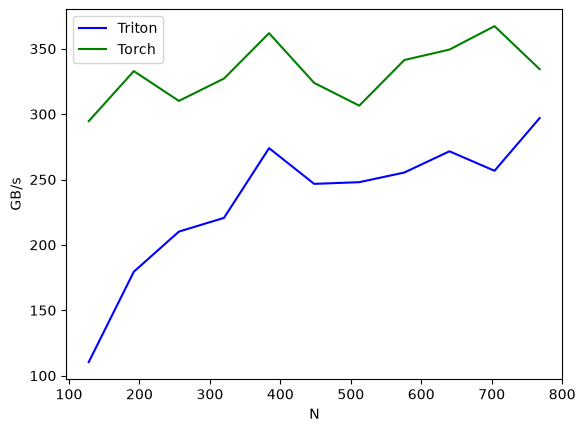

softmax-performance:
        N      Triton       Torch
0   128.0  110.326707  294.611724
1   192.0  179.475721  332.884451
2   256.0  210.158684  310.105458
3   320.0  220.652171  327.213655
4   384.0  273.982870  361.892787
5   448.0  246.663111  323.883747
6   512.0  247.947582  306.486350
7   576.0  255.343152  341.384058
8   640.0  271.580219  349.354657
9   704.0  256.678326  367.285734
10  768.0  296.951449  334.394864


In [5]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=['N'],  # argument names to use as an x-axis for the plot 用作图表 x 轴的参数名
        x_vals=[64 * i for i in range(2, 13)],  # different possible values for `x_name` `x_name` 的不同可能值
        line_arg='provider',  # argument name whose value corresponds to a different line in the plot 参数名，其值对应于图表中不同线条
        line_vals=['triton', 'torch'],  # possible values for `line_arg`` `line_arg` 的可能值
        line_names=[
            "Triton",
            "Torch",
        ],  # label name for the lines 线条的标签名称
        styles=[('blue', '-'), ('green', '-')],  # line styles 线条的样式
        ylabel="GB/s",  # label name for the y-axis y 轴的标签名称
        plot_name="softmax-performance",  # name for the plot. Used also as a file name for saving the plot. 图表的名称，也用作保存图表的文件名
        args={'M': 4096},  # values for function arguments not in `x_names` and `y_name` `x_names` 和 `y_name` 中未包含的函数参数的值
    ))
def benchmark(M, N, provider):
    x = torch.randn(M, N, device='cuda', dtype=torch.float32)
    
    #CUDA Stream 是 GPU 工作的执行队列，用于组织和调度 CUDA Kernel、内存拷贝等 GPU 操作
    #创建一个新的 CUDA Stream（CUDA 流），
    # 然后将它设置为当前使用的 CUDA Stream

    stream = torch.cuda.Stream()
    torch.cuda.set_stream(stream)
    if provider == 'torch':
        ms = triton.testing.do_bench(lambda: torch.softmax(x, axis=-1))
    if provider == 'triton':
        ms = triton.testing.do_bench(lambda: softmax(x))
    gbps = lambda ms: 2 * x.nelement() * x.element_size() * 1e-9 / (ms * 1e-3)
    return gbps(ms)

# def benchmark(M, N, provider):
#     x = torch.randn(M, N, device="cuda", dtype=torch.float32)
#     torch.cuda.synchronize()

#     if provider == "torch":
#         fn = lambda: torch.softmax(x, dim=-1)
#     else:
#         fn = lambda: softmax(x)

#     ms = triton.testing.do_bench(
#         fn,
#         warmup=25,
#         rep=100,
#         return_mode="median",  # 使用 P50 耗时
#     )

#     return 2 * x.numel() * x.element_size() * 1e-6 / ms


benchmark.run(show_plots=True, print_data=True)